In [3]:
import pandas as pd
import numpy as np



In [4]:
df = pd.read_csv('Car_Price_Prediction.csv')
df.head()


,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
0,Honda,Model B,2015,3.9,74176,Petrol,Manual,30246.207931
1,Ford,Model C,2014,1.7,94799,Electric,Automatic,22785.747684
2,BMW,Model B,2006,4.1,98385,Electric,Manual,25760.290347
3,Honda,Model B,2015,2.6,88919,Electric,Automatic,25638.003491
4,Honda,Model C,2004,3.4,138482,Petrol,Automatic,21021.386657


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Make          1000 non-null   str    
 1   Model         1000 non-null   str    
 2   Year          1000 non-null   int64  
 3   Engine Size   1000 non-null   float64
 4   Mileage       1000 non-null   int64  
 5   Fuel Type     1000 non-null   str    
 6   Transmission  1000 non-null   str    
 7   Price         1000 non-null   float64
dtypes: float64(2), int64(2), str(4)
memory usage: 62.6 KB


In [6]:
df.describe()

,Year,Engine Size,Mileage,Price
count,1000.000000,1000.000000,1000.00000,1000.000000
mean,2010.688000,2.798300,97192.48700,25136.615530
std,6.288577,1.024137,59447.31576,5181.401368
min,2000.000000,1.000000,56.00000,6704.953524
25%,2005.000000,1.900000,44768.75000,21587.878370
50%,2011.000000,2.800000,94411.50000,25189.325247
75%,2016.000000,3.700000,148977.75000,28806.368974
max,2021.000000,4.500000,199867.00000,41780.504635


In [9]:
df.describe(include='O')

/tmp/ipykernel_73310/2537740217.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='O')


,Make,Model,Fuel Type,Transmission
count,1000,1000,1000,1000
unique,5,5,3,2
top,Ford,Model B,Diesel,Manual
freq,225,212,344,511


In [10]:
for col in df.select_dtypes('object').columns:
    print(df[col].value_counts())
    print()


Make
Ford      225
Audi      212
Honda     198
Toyota    187
BMW       178
Name: count, dtype: int64

Model
Model B    212
Model C    205
Model A    202
Model D    197
Model E    184
Name: count, dtype: int64

Fuel Type
Diesel      344
Petrol      331
Electric    325
Name: count, dtype: int64

Transmission
Manual       511
Automatic    489
Name: count, dtype: int64



/tmp/ipykernel_73310/1046006997.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes('object').columns:


In [12]:
###استخدمت مكتبة datetime لحساب عمر السيارة

import datetime

df['car age'] = datetime.datetime.now().year - df['Year']
df.head()

,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price,car age
0,Honda,Model B,2015,3.9,74176,Petrol,Manual,30246.207931,11
1,Ford,Model C,2014,1.7,94799,Electric,Automatic,22785.747684,12
2,BMW,Model B,2006,4.1,98385,Electric,Manual,25760.290347,20
3,Honda,Model B,2015,2.6,88919,Electric,Automatic,25638.003491,11
4,Honda,Model C,2004,3.4,138482,Petrol,Automatic,21021.386657,22


In [16]:
%pip install seaborn matplotlib



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt


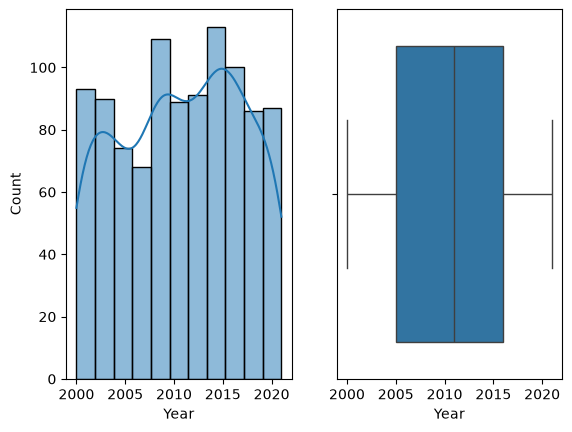

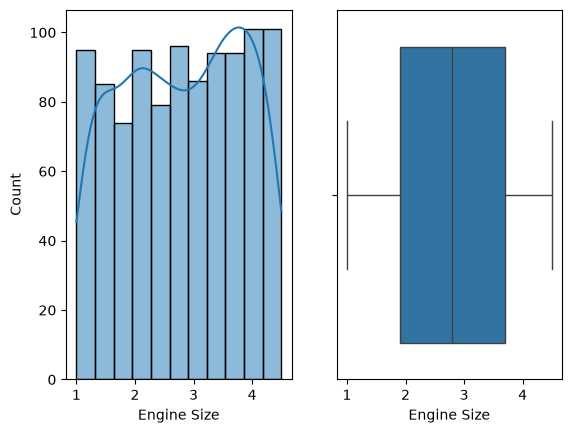

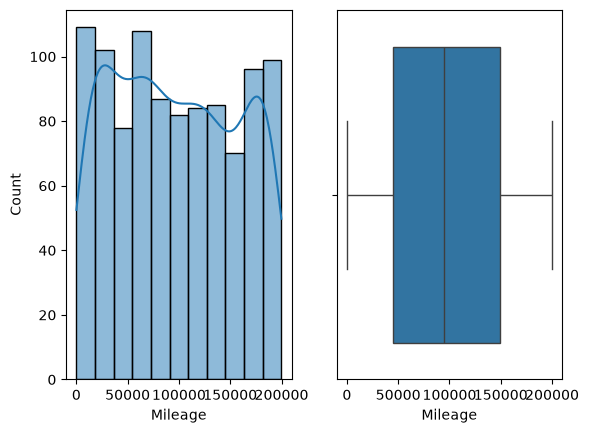

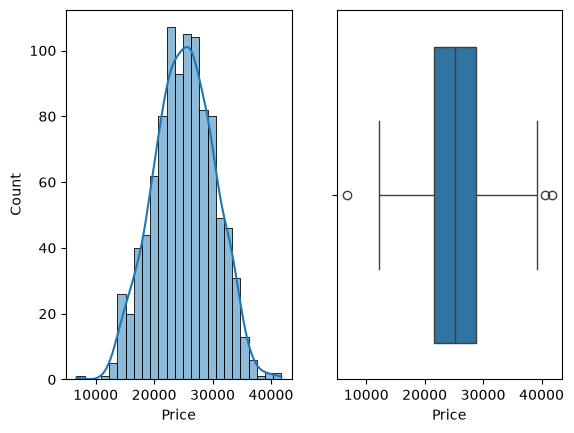

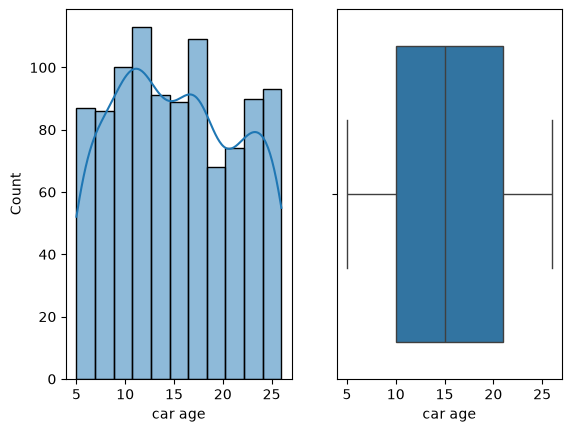

In [18]:
for col in df.select_dtypes('number').columns:
    fig, ax = plt.subplots(1,2)
    sns.histplot(x=df[col],kde=True,ax=ax[0])
    sns.boxplot(x=df[col],ax=ax[1])
    plt.show()
    

In [21]:
###حزفت القيم الشاذة في السعر و ترتيب الاعمده
df.drop(df[(df['Price'] <=10000) | (df['Price'] >=39000)].index,axis=0,inplace=True)
df.reset_index(drop=True,inplace=True)
df


,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price,car age
0,Honda,Model B,2015,3.9,74176,Petrol,Manual,30246.207931,11
1,Ford,Model C,2014,1.7,94799,Electric,Automatic,22785.747684,12
2,BMW,Model B,2006,4.1,98385,Electric,Manual,25760.290347,20
3,Honda,Model B,2015,2.6,88919,Electric,Automatic,25638.003491,11
4,Honda,Model C,2004,3.4,138482,Petrol,Automatic,21021.386657,22
...,...,...,...,...,...,...,...,...,...
990,Toyota,Model D,2002,1.9,5445,Petrol,Manual,22765.597091,24
991,Honda,Model B,2020,3.1,149112,Diesel,Manual,30392.575567,6
992,Ford,Model C,2008,1.9,195387,Petrol,Automatic,16446.892292,18
993,Toyota,Model A,2003,4.4,246,Petrol,Automatic,27396.156708,23


/tmp/ipykernel_73310/3561859696.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes('O').columns:


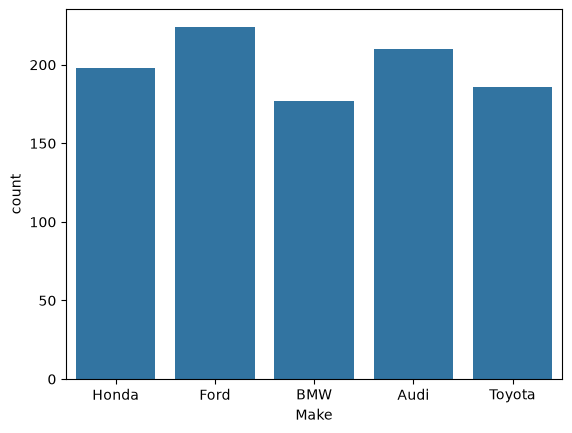

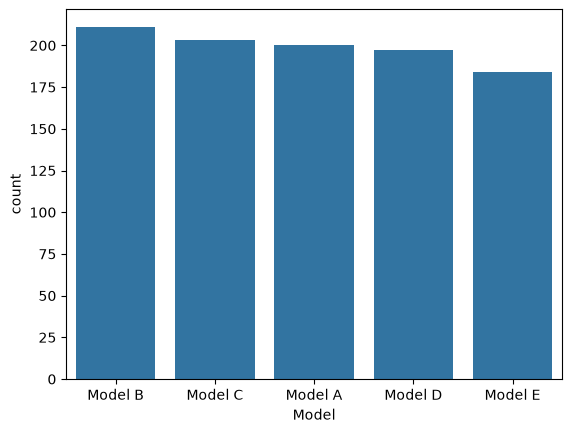

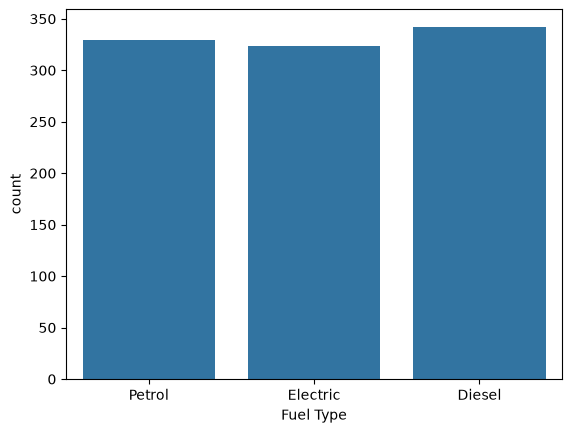

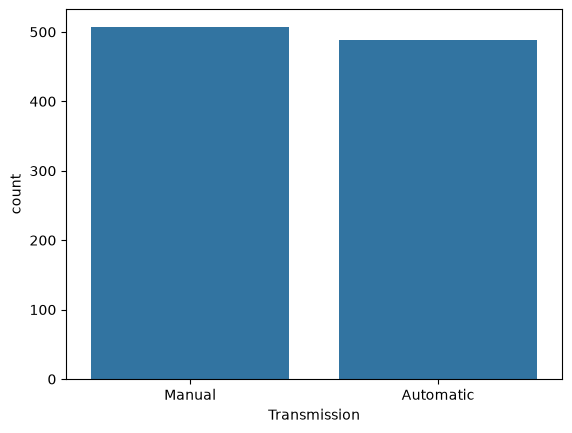

In [22]:
for col in df.select_dtypes('O').columns:
    sns.countplot(x=df[col])
    plt.show()



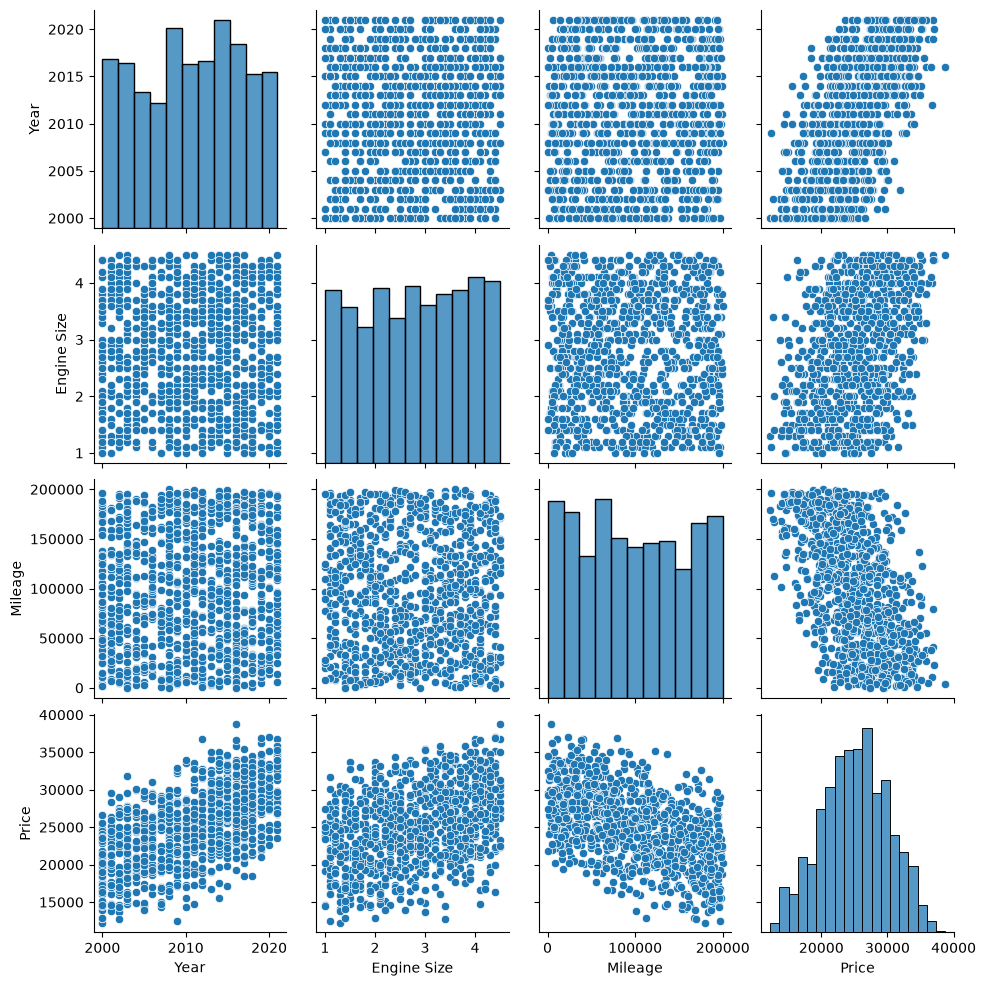

In [23]:
df.drop('car age',axis=1,inplace=True)
sns.pairplot(df)

In [24]:


df.head()




,Make,Model,Year,Engine Size,Mileage,Fuel Type,Transmission,Price
0,Honda,Model B,2015,3.9,74176,Petrol,Manual,30246.207931
1,Ford,Model C,2014,1.7,94799,Electric,Automatic,22785.747684
2,BMW,Model B,2006,4.1,98385,Electric,Manual,25760.290347
3,Honda,Model B,2015,2.6,88919,Electric,Automatic,25638.003491
4,Honda,Model C,2004,3.4,138482,Petrol,Automatic,21021.386657


In [25]:

df.duplicated().sum()

np.int64(0)

In [26]:

df.isna().sum()

Make            0
Model           0
Year            0
Engine Size     0
Mileage         0
Fuel Type       0
Transmission    0
Price           0
dtype: int64

In [27]:
# و هنا بقسم بين التدريب و الاختبار عشان اتفادي الاوفر فيتنج
from sklearn.model_selection import train_test_split

X = df.drop('Price',axis=1)
y = df['Price']

X_train, X_test, y_train,y_test = train_test_split(X,y,test_size=0.2,shuffle=True,random_state=42)
X_train.shape, X_test.shape, y_train.shape,y_test.shape

((796, 7), (199, 7), (796,), (199,))

In [28]:
# هنا بفصل الداتا يسن التدريب و الاختبار 
train_cat = X_train.select_dtypes('O')
test_cat = X_test.select_dtypes('O')
train_cat


/tmp/ipykernel_73310/1426510899.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_cat = X_train.select_dtypes('O')
/tmp/ipykernel_73310/1426510899.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how

,Make,Model,Fuel Type,Transmission
909,Honda,Model B,Diesel,Automatic
925,Audi,Model B,Petrol,Manual
974,Honda,Model D,Diesel,Automatic
765,Ford,Model B,Diesel,Automatic
911,Honda,Model D,Diesel,Automatic
...,...,...,...,...
106,Audi,Model E,Petrol,Manual
270,Toyota,Model C,Electric,Automatic
860,Audi,Model C,Diesel,Automatic
435,Honda,Model C,Diesel,Automatic


In [31]:
#راجع عشان مهم ونت مش فاهم هنا 

from sklearn.preprocessing import OneHotEncoder

onh = OneHotEncoder(sparse_output=False,drop='first')
train_cat_onh = onh.fit_transform(train_cat)
test_cat_onh = onh.transform(test_cat)
train_cat_onh


array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 1., 1.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.]], shape=(796, 11))

In [32]:
#هنا بستخرج الارقام  من الاعمده

train_num = X_train.select_dtypes('number')
test_num = X_test.select_dtypes('number')

train_num

,Year,Engine Size,Mileage
909,2010,2.3,184885
925,2005,2.8,49086
974,2002,3.4,169587
765,2014,4.4,7145
911,2013,3.2,167079
...,...,...,...
106,2004,1.9,86134
270,2013,2.4,108654
860,2002,4.0,106034
435,2010,2.3,85757


In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_num_scale = scaler.fit_transform(train_num)
test_num_scale = scaler.transform(test_num)

train_num_scale



array([[-0.10711784, -0.50673092,  1.47661087],
       [-0.90698468, -0.01554995, -0.84277913],
       [-1.38690478,  0.57386722,  1.21532744],
       ...,
       [-1.38690478,  1.16328439,  0.12986884],
       [-0.10711784, -0.50673092, -0.21645382],
       [ 1.33264245,  0.18092244,  1.34267279]], shape=(796, 3))

In [35]:

# هنا حضرنا و عزلت عشان اجهز المودل
train = np.c_[train_cat_onh,train_num_scale]
test = np.c_[test_cat_onh,test_num_scale]
train



array([[ 0.        ,  0.        ,  1.        , ..., -0.10711784,
        -0.50673092,  1.47661087],
       [ 0.        ,  0.        ,  0.        , ..., -0.90698468,
        -0.01554995, -0.84277913],
       [ 0.        ,  0.        ,  1.        , ..., -1.38690478,
         0.57386722,  1.21532744],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -1.38690478,
         1.16328439,  0.12986884],
       [ 0.        ,  0.        ,  1.        , ..., -0.10711784,
        -0.50673092, -0.21645382],
       [ 0.        ,  0.        ,  0.        , ...,  1.33264245,
         0.18092244,  1.34267279]], shape=(796, 14))

In [36]:
##

target_scaler = StandardScaler()
y_train_scale = target_scaler.fit_transform(np.array(y_train).reshape(-1,1))
y_test_scale = target_scaler.transform(np.array(y_test).reshape(-1,1))
y_test_scale

array([[ 1.05552041],
       [ 0.25398881],
       [ 1.47961174],
       [ 1.79154069],
       [-0.04944783],
       [ 0.42067229],
       [ 0.32966012],
       [-1.65171287],
       [ 0.03914082],
       [-0.05896318],
       [ 0.83015151],
       [ 0.19185054],
       [-0.32875603],
       [ 0.40510163],
       [ 0.21643086],
       [-0.81719425],
       [ 0.27548195],
       [-1.19689594],
       [ 1.3122407 ],
       [-0.67988707],
       [ 1.95365171],
       [ 1.15592732],
       [ 0.20745638],
       [-0.32584252],
       [-0.99842494],
       [ 0.84736103],
       [ 0.30839316],
       [-0.62830892],
       [-0.98249495],
       [-0.21811598],
       [ 1.49754455],
       [-0.56562848],
       [ 0.62114524],
       [ 1.2582598 ],
       [-0.62708616],
       [-1.55856844],
       [ 0.78600657],
       [-0.85876758],
       [ 1.47062111],
       [ 0.05523124],
       [-0.80373662],
       [-1.53726355],
       [-0.18591682],
       [ 1.50759433],
       [-0.26006267],
       [-1

In [37]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(train,y_train_scale)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 14)","[[-0.01, 0.01,-0.04,..., 0.64, 0.38,-0.56]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-0.01]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,14
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(14)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](14,)","[28.85,28.29,27.67,..., 9.42, 5.85, 5.54]"


In [38]:
lr.score(train,y_train_scale) * 100


83.91280891801074

In [39]:
# الموديل خمن أسعار بيانات الاختبار، ورجعنا الأسعار بالجنيه/الدولار الحقيقي، وقسنا نسبة دقته ومقدار الغلط في التوقع

from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

y_pred = lr.predict(test)

y_pred = target_scaler.inverse_transform(y_pred)

print(f"RMSE: {np.sqrt(mean_squared_error(y_test,y_pred))}")
print(f"R2: {r2_score(y_test,y_pred) * 100:.2f} %")

RMSE: 2093.793443606538
R2: 83.11 %


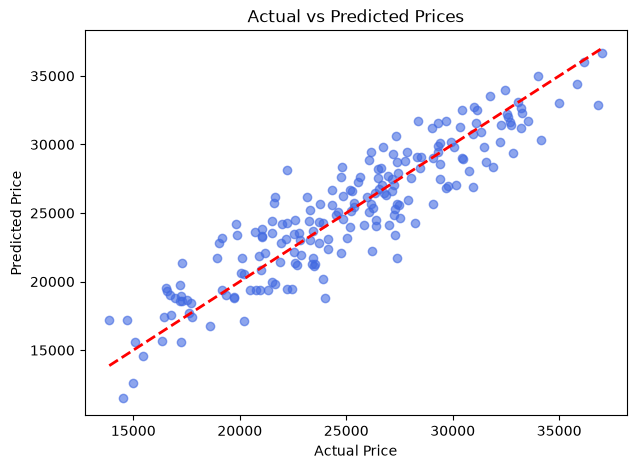

In [40]:
# رسم بياني مقارنه بين الأسعار الحقيقية و أسعار الموديل توقعها
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.6, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], '--r', lw=2)
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Prices')
plt.show()

In [41]:
import joblib

joblib.dump(lr, 'car_price_model.pkl')
joblib.dump(target_scaler, 'target_scaler.pkl')

['target_scaler.pkl']